# SpaQFormer run: Human NSCLC (Lung9_1)

## 1. Imports

In [1]:
import json
import os
import sys
from pathlib import Path

# Resolve package, configuration, and output paths from the repository root.
if Path.cwd().name == "Tutorial":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml

from SpaQFormer.evaluate import (
    compute_label_metrics,
    label_summary,
    valid_label_mask,
)
from SpaQFormer.trainer import SpaQFormer

plt.rcParams.update({
    "font.family": "Arial",
    "font.sans-serif": ["Arial"],
    "axes.unicode_minus": False,
})

c:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\torch\cuda\__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


## 2. Dataset paths and configuration

In [2]:
DATASET_NAME = "NSCLC"

# Update these two paths to match the local data location.
SC_FILE = Path(r"C:\Code\Data\SpatialMap\NSCLC_9_1_reference.h5ad")
SRT_FILE = Path(r"C:\Code\Data\SpatialMap\NSCLC_9_1_target.h5ad")
CONFIG_FILE = Path("Config") / "Config_NSCLC.yaml"
OUTPUT_DIR = Path("logs") / "spaqformer_nsclc_best"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

with CONFIG_FILE.open("r", encoding="utf-8") as file:
    config = yaml.safe_load(file)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## 3. Initialize SpaQFormer

In [3]:
model = SpaQFormer(
    sc_file=SC_FILE,
    srt_file=SRT_FILE,
    device=device,
    **config,
)

print(f"Device: {device}")
print(f"sc_x: {model.sc_x.shape}")
print(f"srt_x: {model.srt_x.shape}")
print(f"srt_edges: {model.srt_edges.shape}")
print(f"num_classes: {model.num_classes}")
print(f"hidden_dim: {model.hidden_dim}")

c:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
c:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
c:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
c:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
c:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_mtx from `anndata` is deprecated. Import annd

Device: cuda
sc_x: (49467, 952)
srt_x: (85904, 952)
srt_edges: (1718080, 2)
num_classes: 15
hidden_dim: 64


## 4. Stage 1: pretrain once on the scRNA-seq reference

In [4]:
model.pretrain()

SpaQFormer pretrain:   0%|          | 0/50 [00:00<?, ?epoch/s]

PretrainModel(
  (encoder): Encoder(
    (layers): ModuleList(
      (0): Linear(in_features=952, out_features=512, bias=True)
      (1): Linear(in_features=512, out_features=64, bias=True)
    )
  )
  (cls): Classifier(
    (fc): Linear(in_features=64, out_features=15, bias=True)
  )
  (decoder): Decoder(
    (layers): ModuleList(
      (0): Linear(in_features=64, out_features=512, bias=True)
      (1): Linear(in_features=512, out_features=952, bias=True)
    )
  )
)

## 5. Stages 2-4: pseudo-label, build prototypes, and annotate every target

In [5]:
pseudo_labels, pseudo_mask = model.pseudo_label()


reference_prototypes = model.build_prototypes()

annotation = model.annotate(
    use_cluster=True,
    num_parts=10,
    cluster_batch_size=1,
    open_set=False,
)

Computing METIS partitioning...
Done!


SpaQFormer cluster annotate:   0%|          | 0/100 [00:00<?, ?epoch/s]

## 6. Save SpaQFormer outputs

In [6]:
source_adata = ad.read_h5ad(SRT_FILE, backed="r")
class_names = [
    str(model.inverse_dict[index])
    for index in range(model.num_classes)
]
result_adata = ad.AnnData(obs=source_adata.obs.copy())
result_adata.obs["SpaQFormer_annotation"] = pd.Categorical(
    np.asarray(model.annotation, dtype=str),
    categories=class_names,
)
result_adata.obsm["X_SpaQFormer"] = np.asarray(
    model.srt_qformer_embeddings,
    dtype=np.float32,
)

output_h5ad = os.path.join(
    OUTPUT_DIR,
    "spaqformer_nsclc_best_results.h5ad",
)
result_adata.write_h5ad(output_h5ad, compression="gzip")
source_adata.file.close()
print(f"Saved AnnData results to: {output_h5ad}")

c:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


Saved AnnData results to: logs\spaqformer_nsclc_best\spaqformer_nsclc_best_results.h5ad


## 7. Evaluate

In [7]:
LABEL_COL = "label"
EXCLUDE_LABEL = "unlabeled"

all_labels = result_adata.obs[LABEL_COL].astype(str).to_numpy()
valid_mask = valid_label_mask(all_labels, exclude_label=EXCLUDE_LABEL)
summary = label_summary(all_labels, exclude_label=EXCLUDE_LABEL)

gt = all_labels[valid_mask]
pred = result_adata.obs["SpaQFormer_annotation"].astype(str).to_numpy()[valid_mask]

metrics = compute_label_metrics(gt, pred)
metrics_df = pd.DataFrame(metrics, index=["SpaQFormer_best_closed_set"]).T

print(json.dumps(summary, indent=2, ensure_ascii=False))
print(metrics_df.to_string())

{
  "total_spots": 85904,
  "excluded_label": "unlabeled",
  "excluded_spots": 0,
  "valid_spots": 85904,
  "n_types_with_excluded": 15,
  "n_valid_types": 15,
  "valid_types": [
    "B-cell",
    "NK",
    "T CD4",
    "T CD8",
    "Treg",
    "endothelial",
    "epithelial",
    "fibroblast",
    "mDC",
    "macrophage",
    "mast",
    "neutrophil",
    "pDC",
    "plasmablast",
    "tumors"
  ]
}
                    SpaQFormer_best_closed_set
acc                                   0.798997
precision_macro                       0.491349
recall_macro                          0.484478
f1_macro                              0.464301
precision_weighted                    0.787982
recall_weighted                       0.798997
f1_weighted                           0.787853
ari                                   0.846240
nmi                                   0.620397
kappa                                 0.731056
mcc                                   0.732213
n_eval                          

## 8. Ground truth and SpaQFormer spatial annotations

c:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


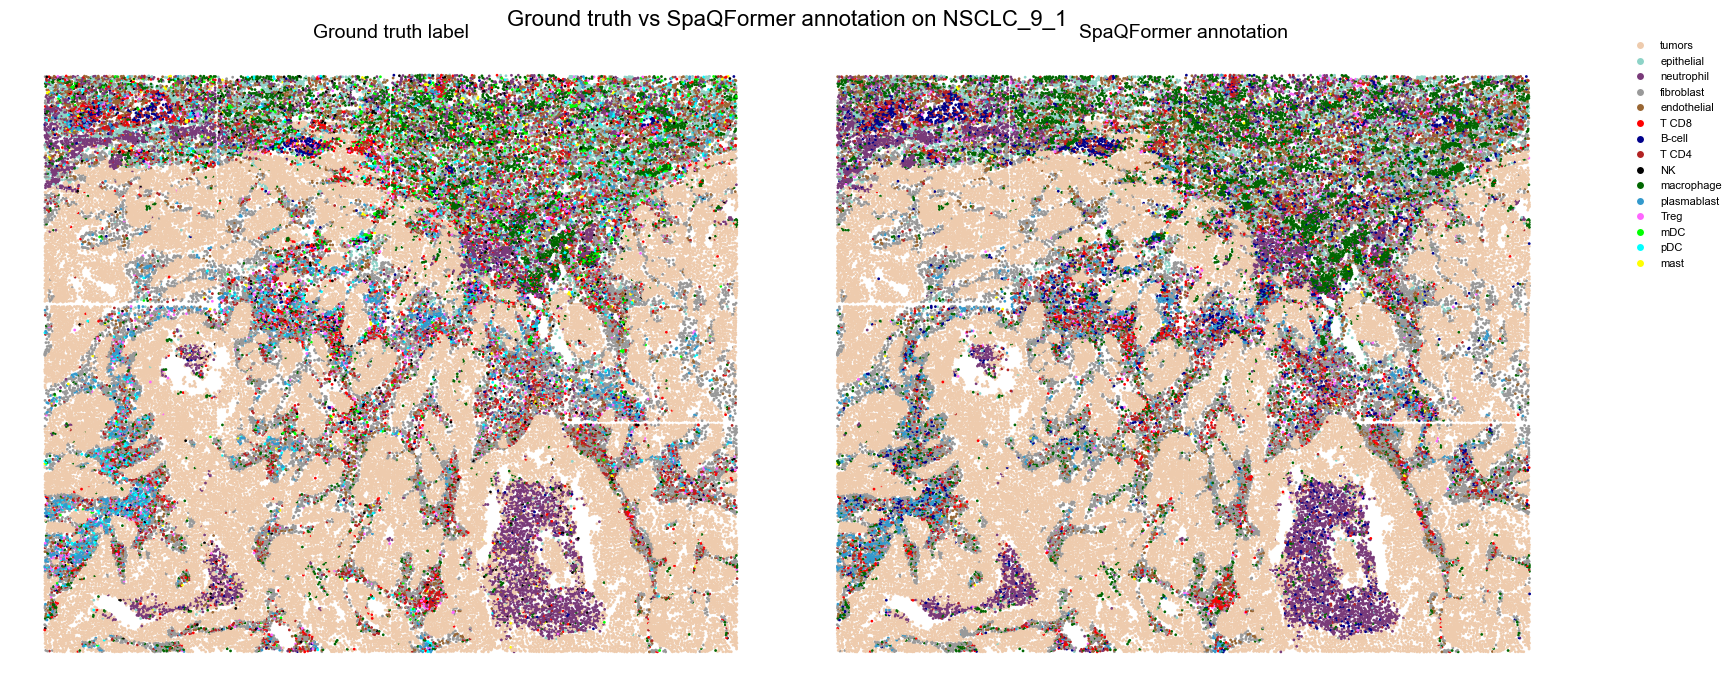

In [8]:
srt_adata_mem = ad.read_h5ad(SRT_FILE)

plot_df = pd.DataFrame({
    "x": srt_adata_mem.obs["x"].to_numpy(),
    "y": srt_adata_mem.obs["y"].to_numpy(),
    "label": srt_adata_mem.obs["label"].astype(str).to_numpy(),
    "SpaQFormer": result_adata.obs["SpaQFormer_annotation"].astype(str).to_numpy(),
})

category_color_mapping = {
    "tumors": "#eecbad",
    "epithelial": "#8dd3c7",
    "neutrophil": "#793a79",
    "fibroblast": "#999999",
    "endothelial": "#996633",
    "T CD8": "#ff0000",
    "B-cell": "#00008b",
    "T CD4": "#b22222",
    "NK": "#000000",
    "macrophage": "#006600",
    "plasmablast": "#3399cc",
    "Treg": "#ff66ff",
    "mDC": "#00ff00",
    "pDC": "#00ffff",
    "mast": "#ffff00",
}

observed_cell_types = (
    set(plot_df["label"].unique()) | set(plot_df["SpaQFormer"].unique())
)
all_cell_types = [
    cell_type
    for cell_type in category_color_mapping
    if cell_type in observed_cell_types
]
color_map = category_color_mapping

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharex=True, sharey=True)

for ax, col, title in zip(
    axes,
    ["label", "SpaQFormer"],
    ["Ground truth label", "SpaQFormer annotation"],
):
    colors = plot_df[col].map(color_map)

    ax.scatter(
        plot_df["x"],
        plot_df["y"],
        c=colors,
        s=4,
        linewidths=0,
    )
    ax.set_aspect("equal", adjustable="box")
    ax.axis("off")
    ax.set_title(title, fontsize=14)
    
axes[0].invert_yaxis()

handles = [
    plt.Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor=color_map[cell_type],
        markersize=6,
        label=cell_type,
    )
    for cell_type in all_cell_types
]

fig.legend(
    handles=handles,
    bbox_to_anchor=(1.02, 0.95),
    loc="upper left",
    frameon=False,
    fontsize=8,
)

fig.suptitle("Ground truth vs SpaQFormer annotation on NSCLC_9_1", fontsize=16)

plt.tight_layout()
plt.show()

## 9. Cell-type gene attribution with IG, GS, and OC

In [9]:
from SpaQFormer import SpaQFormerExplainer


explain_output_dir = OUTPUT_DIR / "explain"
explain_output_dir.mkdir(parents=True, exist_ok=True)

explainer = SpaQFormerExplainer(
    model,
    num_parts=50,
)

all_results = explainer.explain_all_cell_types(
    max_cells=50,
    methods=("ig", "gs", "oc"),
    top_k=20,
    ig_steps=16,
    gs_samples=8,
    perturbations_per_eval=16,
)


all_gene_score_tables = []
all_top_gene_tables = []

for cell_type, explanation in all_results.items():
    gene_scores = explanation["gene_scores"].copy()
    gene_scores.insert(0, "cell_type", cell_type)
    all_gene_score_tables.append(gene_scores)

    top_genes = explanation["top_genes"].copy()
    top_genes.insert(0, "cell_type", cell_type)
    all_top_gene_tables.append(top_genes)


all_gene_scores_df = pd.concat(all_gene_score_tables, ignore_index=True)
all_top_genes_df = pd.concat(all_top_gene_tables, ignore_index=True)

all_gene_scores_path = (
    explain_output_dir / "SpaQFormer_NSCLC_all_cell_types_all_gene_scores.csv"
)
all_top_genes_path = (
    explain_output_dir / "SpaQFormer_NSCLC_all_cell_types_top20_genes.csv"
)
all_gene_scores_df.to_csv(
    all_gene_scores_path,
    index=False,
    encoding="utf-8-sig",
)
all_top_genes_df.to_csv(
    all_top_genes_path,
    index=False,
    encoding="utf-8-sig",
)

print(f"All gene scores: {all_gene_scores_path}")
print(f"Top 20 genes: {all_top_genes_path}")
display(all_top_genes_df.groupby("cell_type").head(10))

Computing METIS partitioning...
Done!


Skip NK: No cells were predicted as NK.
Skip pDC: No cells were predicted as pDC.
All gene scores: logs\spaqformer_nsclc_best\explain\SpaQFormer_NSCLC_all_cell_types_all_gene_scores.csv
Top 20 genes: logs\spaqformer_nsclc_best\explain\SpaQFormer_NSCLC_all_cell_types_top20_genes.csv


,cell_type,gene,ig_score,ig_rank,gs_score,gs_rank,oc_score,oc_rank,borda_score,final_rank
0,B-cell,IGHA1,0.456631,1,0.427985,1,0.451475,2,2855.0,1
1,B-cell,IGHM,0.379246,2,0.378323,2,0.533566,1,2854.0,2
2,B-cell,IGKC,0.349257,3,0.374356,3,0.182935,3,2850.0,3
3,B-cell,MZT2A,0.102590,5,0.110620,5,0.036656,5,2844.0,4
4,B-cell,CD37,0.069884,6,0.069237,6,0.033124,6,2841.0,5
...,...,...,...,...,...,...,...,...,...,...
245,tumors,HLA-A,0.167753,6,0.141116,8,0.059128,11,2834.0,6
246,tumors,TUBB,0.128204,7,0.103946,11,0.047262,12,2829.0,7
247,tumors,MIF,0.050325,27,0.195866,3,0.374463,3,2826.0,8
248,tumors,GSTP1,0.184580,4,0.149222,6,0.026654,30,2819.0,9
